# FTL Syria — AI for Climate
## Decision Trees for Climate Data: Classification and Regression

**Bootcamp lesson demonstration | Python + scikit-learn**

This notebook follows the concepts in the *ML Week 4 — Decision Tree* slides:

- Decision trees as supervised learning methods for **classification** and **regression**.
- Root nodes, branches and leaf nodes.
- Choosing splits using impurity measures such as **Gini impurity** and **entropy / information gain**.
- Stopping criteria such as `max_depth` and `min_samples_leaf`.
- One-hot encoding categorical features and splitting on continuous features.
- Evaluating models, identifying overfitting and introducing Random Forests.

> **Data note:** All weather observations in this notebook are synthetically generated for teaching. They are not measured Syrian weather data and must not be used for operational forecasts or climate-risk decisions. The examples are designed to demonstrate an ML workflow, not to represent Syria's climate accurately.

### Learning outcomes
By the end, you should be able to train and evaluate a decision tree that predicts:
1. **Classification:** whether tomorrow is a wet day (yes/no).
2. **Regression:** how much rainfall may occur tomorrow (millimetres).

Run the notebook from top to bottom. Code comments explain each important step.

## 1. What is a decision tree?

A decision tree repeatedly asks questions about input features and divides observations into smaller groups.

- **Root node:** the first split in the tree.
- **Branches:** the outcomes of a split.
- **Internal nodes:** later decisions.
- **Leaf nodes:** final outputs. A classifier predicts a class (and can estimate class probabilities); a regressor predicts a number.

Example questions might be: Is humidity above a threshold? Is pressure below a threshold? Is the season winter?

### Classification versus regression

| Decision tree type | Target | Example in this notebook | Split objective |
|---|---|---|---|
| `DecisionTreeClassifier` | Category | Wet day / not wet day | Reduce class impurity (Gini or entropy) |
| `DecisionTreeRegressor` | Number | Rainfall tomorrow in mm | Reduce prediction error, commonly squared error |

Trees can express nonlinear relationships and interactions between features, but a very deep tree can memorise training examples and perform poorly on future data.

## 2. Import the libraries

We use pandas and NumPy for data handling, Matplotlib for visualisation, and scikit-learn for preprocessing, models and evaluation metrics.

In [1]:
# Import tools for tables and numerical calculations.
import numpy as np
import pandas as pd

# Import plotting tools for charts and the decision-tree diagram.
import matplotlib.pyplot as plt

# Import preprocessing tools. Pipelines ensure preprocessing is fitted on training data only.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Import decision-tree and ensemble models.
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor

# Import model-evaluation metrics.
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

# Use a fixed seed to make this demonstration reproducible.
RANDOM_STATE = 42

# Display tables in a readable format.
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Create a synthetic climate dataset

To keep the lesson reproducible and independent of internet access, we generate several years of *illustrative* daily weather-like observations. The synthetic data has seasonal patterns and some persistence between consecutive days so that earlier observations contain signals about the next day.

Features available on day *t*:
- rainfall on day *t* (mm)
- maximum temperature on day *t* (°C)
- relative humidity on day *t* (%)
- atmospheric pressure on day *t* (hPa)
- wind speed on day *t* (km/h)
- season on day *t* (categorical)

Targets:
- rainfall on day *t + 1* (a numerical target for regression)
- whether rainfall on day *t + 1* is at least 1 mm (a binary target for classification)

The `1 mm` wet-day threshold is an illustrative teaching choice. Real projects should document and justify their threshold.

In [2]:
# Set a fixed random generator so results can be reproduced by other students.
rng = np.random.default_rng(RANDOM_STATE)

# Create five years of daily dates. This is synthetic teaching data, not a real weather archive.
n_days = 5 * 365
dates = pd.date_range(start="2019-01-01", periods=n_days, freq="D")
day_of_year = dates.dayofyear.to_numpy()
months = dates.month.to_numpy()

# Assign a season based on month so the model can learn from a categorical feature.
season = np.select(
    [np.isin(months, [12, 1, 2]), np.isin(months, [3, 4, 5]),
     np.isin(months, [6, 7, 8]), np.isin(months, [9, 10, 11])],
    ["winter", "spring", "summer", "autumn"],
    default="unknown"
)

# Create a slowly changing latent weather regime to give neighbouring days some continuity.
# This hidden state is only used to generate synthetic observations; it is NOT a model input.
weather_regime = np.zeros(n_days)
for i in range(1, n_days):
    # Keep part of yesterday's regime and add a random innovation.
    weather_regime[i] = 0.90 * weather_regime[i - 1] + rng.normal(0, 0.35)

# Create a smooth annual temperature cycle, with random daily variation.
annual_phase = 2 * np.pi * (day_of_year - 100) / 365.25
tmax_c = 23 + 10 * np.sin(annual_phase) - 1.5 * weather_regime + rng.normal(0, 3.0, n_days)

# Generate humidity. Values are clipped to a plausible percentage range for the exercise.
humidity_pct = np.clip(
    48 - 13 * np.sin(annual_phase) + 12 * weather_regime + rng.normal(0, 8, n_days),
    15, 98
)

# Generate atmospheric pressure and wind speed with random variation.
pressure_hpa = 1014 - 2.3 * weather_regime + rng.normal(0, 2.5, n_days)
wind_kmh = np.clip(12 + 2 * np.abs(weather_regime) + rng.normal(0, 4, n_days), 0, 45)

# Define a seasonal adjustment to make rainfall more likely in some seasons in this synthetic example.
seasonal_rain_adjustment = np.select(
    [season == "winter", season == "spring", season == "summer", season == "autumn"],
    [0.65, 0.20, -0.80, 0.05],
    default=0.0
)

# Generate daily rainfall amounts. Rain occurrence depends probabilistically on humidity,
# pressure, season, and whether the previous day was wet. The coefficients are illustrative.
rain_mm = np.zeros(n_days)
for i in range(n_days):
    # Use yesterday's rainfall as a simple persistence signal when generating today's weather.
    previous_wet = 1 if (i > 0 and rain_mm[i - 1] >= 1.0) else 0

    # Calculate a synthetic logit score for the probability of rain.
    logit = (
        -2.1
        + 0.065 * (humidity_pct[i] - 50)
        - 0.70 * (pressure_hpa[i] - 1013)
        + seasonal_rain_adjustment[i]
        + 0.35 * previous_wet
    )

    # Convert the logit to a probability between 0 and 1.
    probability_of_rain = 1 / (1 + np.exp(-logit))

    # Sample whether rain occurs, then sample a positive amount for wet days.
    if rng.random() < probability_of_rain:
        # A Gamma distribution gives a range of positive rainfall amounts, including occasional larger values.
        rain_mm[i] = rng.gamma(shape=1.8, scale=3.5)
    else:
        rain_mm[i] = 0.0

# Combine the generated variables in one time-ordered table.
weather = pd.DataFrame({
    "date": dates,
    "season": season,
    "rain_today_mm": rain_mm,
    "tmax_today_c": tmax_c,
    "humidity_today_pct": humidity_pct,
    "pressure_today_hpa": pressure_hpa,
    "wind_today_kmh": wind_kmh,
})

# Add a small amount of missingness in selected input features so we can demonstrate imputation.
# Targets are not intentionally made missing here.
for column in ["humidity_today_pct", "wind_today_kmh"]:
    # Randomly choose 2% of rows to mark as missing in this feature.
    missing_rows = rng.choice(weather.index, size=int(0.02 * len(weather)), replace=False)
    weather.loc[missing_rows, column] = np.nan

print("Synthetic dataset created:", weather.shape)
weather.head()

Synthetic dataset created: (1825, 7)


,date,season,rain_today_mm,tmax_today_c,humidity_today_pct,pressure_today_hpa,wind_today_kmh
0,2019-01-01,winter,0.000000,10.448387,61.299705,1014.672964,12.285059
1,2019-01-02,winter,3.115763,14.927506,73.630138,1011.101722,12.868825
2,2019-01-03,winter,0.000000,16.031426,59.775282,1012.412350,10.140712
3,2019-01-04,winter,0.000000,17.676767,68.041022,1015.539188,9.822214
4,2019-01-05,winter,0.000000,9.869029,70.908632,1015.415169,12.222655


## 4. Inspect the data before modelling

Always inspect the dataset before training a model. Check its dimensions, data types, missing values and summary statistics. In a real climate project, this is also where you would validate units, station metadata, dates, sensor ranges and data provenance.

In [3]:
# Inspect the first few observations to confirm the columns look as expected.
display(weather.head(10))

# Check data types and number of non-missing values in each column.
weather.info()

# Count missing values so we know which features need preprocessing.
print("\nMissing values by column:")
print(weather.isna().sum())

# Review numeric summaries to spot obviously unusual values.
display(weather.select_dtypes(include=np.number).describe().T)

,date,season,rain_today_mm,tmax_today_c,humidity_today_pct,pressure_today_hpa,wind_today_kmh
0,2019-01-01,winter,0.000000,10.448387,61.299705,1014.672964,12.285059
1,2019-01-02,winter,3.115763,14.927506,73.630138,1011.101722,12.868825
2,2019-01-03,winter,0.000000,16.031426,59.775282,1012.412350,10.140712
3,2019-01-04,winter,0.000000,17.676767,68.041022,1015.539188,9.822214
4,2019-01-05,winter,0.000000,9.869029,70.908632,1015.415169,12.222655
5,2019-01-06,winter,0.000000,12.885136,61.541921,1012.385042,12.559389
6,2019-01-07,winter,0.000000,16.428107,54.321379,1017.489054,11.820706
7,2019-01-08,winter,0.000000,14.169683,51.162257,1014.196516,14.624763
8,2019-01-09,winter,0.000000,10.711267,67.818446,1015.671358,6.158427
9,2019-01-10,winter,0.000000,15.212013,46.016266,1019.022972,10.365622


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                1825 non-null   datetime64[ns]
 1   season              1825 non-null   object        
 2   rain_today_mm       1825 non-null   float64       
 3   tmax_today_c        1825 non-null   float64       
 4   humidity_today_pct  1789 non-null   float64       
 5   pressure_today_hpa  1825 non-null   float64       
 6   wind_today_kmh      1789 non-null   float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 99.9+ KB

Missing values by column:
date                   0
season                 0
rain_today_mm          0
tmax_today_c           0
humidity_today_pct    36
pressure_today_hpa     0
wind_today_kmh        36
dtype: int64


,count,mean,std,min,25%,50%,75%,max
rain_today_mm,1825.0,1.134086,3.115930,0.000000,0.000000,0.000000,0.000000,27.215038
tmax_today_c,1825.0,23.272694,7.883945,2.726519,16.476773,23.341703,29.935612,41.950088
humidity_today_pct,1789.0,46.113061,15.714122,15.000000,34.492709,45.936175,56.996890,97.950122
pressure_today_hpa,1825.0,1014.431162,3.179302,1003.377323,1012.294320,1014.485739,1016.549537,1023.663382
wind_today_kmh,1789.0,13.203070,4.184424,0.000000,10.507340,13.198247,15.974157,29.119363


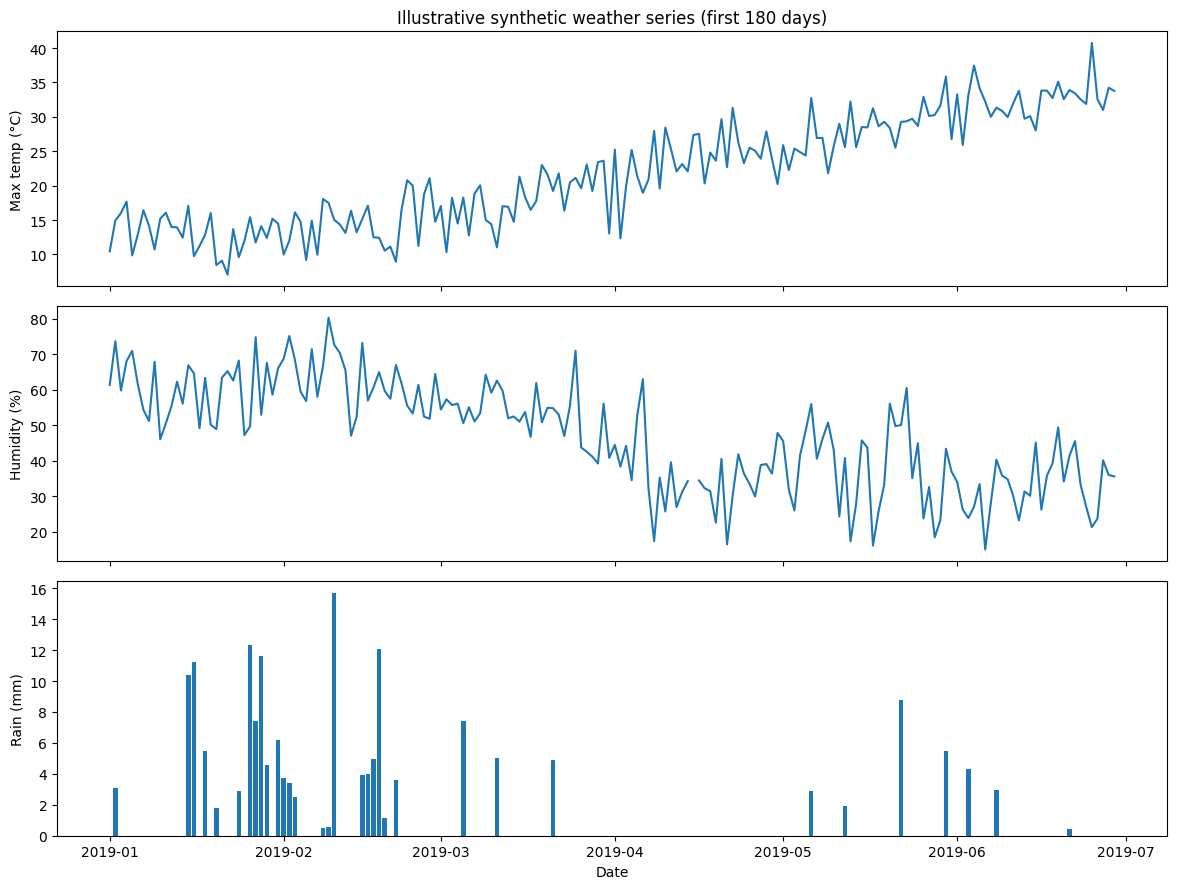

In [4]:
# Plot the first 180 days to see how the synthetic variables change over time.
# These are generated values and should not be interpreted as a real Syrian seasonal profile.
plot_window = weather.iloc[:180]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

# Plot temperature.
axes[0].plot(plot_window["date"], plot_window["tmax_today_c"])
axes[0].set_ylabel("Max temp (°C)")
axes[0].set_title("Illustrative synthetic weather series (first 180 days)")

# Plot humidity.
axes[1].plot(plot_window["date"], plot_window["humidity_today_pct"])
axes[1].set_ylabel("Humidity (%)")

# Plot rainfall amounts, including dry days at zero.
axes[2].bar(plot_window["date"], plot_window["rain_today_mm"])
axes[2].set_ylabel("Rain (mm)")
axes[2].set_xlabel("Date")

# Keep the layout legible when labels are displayed.
plt.tight_layout()
plt.show()

## 5. Create the next-day targets correctly

The task is to make a prediction using information known on day *t* about rainfall on day *t + 1*.

- Regression target: `rain_tomorrow_mm`.
- Classification target: `wet_tomorrow`, where 1 means tomorrow's rainfall is at least 1 mm and 0 means it is below 1 mm.

The final row has no next-day target in this small dataset, so it is removed. The input columns only contain observations from the current day. This alignment is important to avoid accidentally using tomorrow's information as an input.

In [5]:
# Copy the data so the original synthetic weather table remains unchanged.
data = weather.copy()

# Shift rainfall by one row to attach the next day's measured amount to today's features.
# The dataset is already sorted by date, and there is one continuous synthetic series.
data["rain_tomorrow_mm"] = data["rain_today_mm"].shift(-1)

# Convert the numerical rainfall target into a binary class using the chosen 1 mm threshold.
# A value of 1 means 'wet day'; a value of 0 means 'not a wet day' under this definition.
WET_DAY_THRESHOLD_MM = 1.0
data["wet_tomorrow"] = (
    data["rain_tomorrow_mm"] >= WET_DAY_THRESHOLD_MM
).astype("Int64")

# Remove only rows without a known next-day target (the final row).
data = data.dropna(subset=["rain_tomorrow_mm", "wet_tomorrow"]).copy()

# Convert the target label to an integer after removing missing targets.
data["wet_tomorrow"] = data["wet_tomorrow"].astype(int)

# List the predictors that will be available at prediction time.
feature_columns = [
    "rain_today_mm",
    "tmax_today_c",
    "humidity_today_pct",
    "pressure_today_hpa",
    "wind_today_kmh",
    "season",
]

# Separate the input feature table and the two different target variables.
X = data[feature_columns].copy()
y_classification = data["wet_tomorrow"].copy()
y_regression = data["rain_tomorrow_mm"].copy()

print("Features:", feature_columns)
print("Rows available after target alignment:", len(data))
print("Wet-day threshold:", WET_DAY_THRESHOLD_MM, "mm")
display(data[["date"] + feature_columns + ["rain_tomorrow_mm", "wet_tomorrow"]].head(8))

Features: ['rain_today_mm', 'tmax_today_c', 'humidity_today_pct', 'pressure_today_hpa', 'wind_today_kmh', 'season']
Rows available after target alignment: 1824
Wet-day threshold: 1.0 mm


,date,rain_today_mm,tmax_today_c,humidity_today_pct,pressure_today_hpa,wind_today_kmh,season,rain_tomorrow_mm,wet_tomorrow
0,2019-01-01,0.000000,10.448387,61.299705,1014.672964,12.285059,winter,3.115763,1
1,2019-01-02,3.115763,14.927506,73.630138,1011.101722,12.868825,winter,0.000000,0
2,2019-01-03,0.000000,16.031426,59.775282,1012.412350,10.140712,winter,0.000000,0
3,2019-01-04,0.000000,17.676767,68.041022,1015.539188,9.822214,winter,0.000000,0
4,2019-01-05,0.000000,9.869029,70.908632,1015.415169,12.222655,winter,0.000000,0
5,2019-01-06,0.000000,12.885136,61.541921,1012.385042,12.559389,winter,0.000000,0
6,2019-01-07,0.000000,16.428107,54.321379,1017.489054,11.820706,winter,0.000000,0
7,2019-01-08,0.000000,14.169683,51.162257,1014.196516,14.624763,winter,0.000000,0


Classification target counts (0 = not wet; 1 = wet):
wet_tomorrow
0    1519
1     305
Name: count, dtype: int64

Classification target proportions:
wet_tomorrow
0    0.833
1    0.167
Name: proportion, dtype: float64


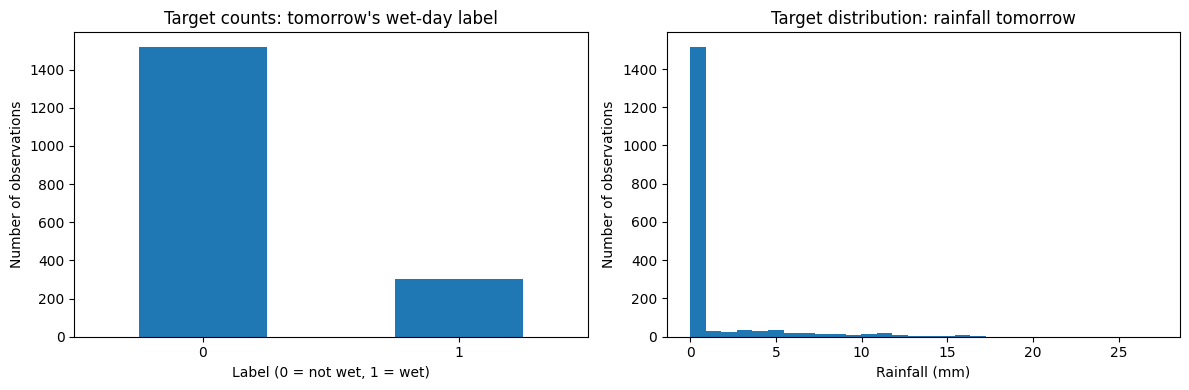

In [6]:
# Summarise the target for each task so we know what the models will learn.
print("Classification target counts (0 = not wet; 1 = wet):")
print(y_classification.value_counts().sort_index())
print("\nClassification target proportions:")
print(y_classification.value_counts(normalize=True).sort_index().round(3))

# Plot the distribution of tomorrow's rainfall. A zero-heavy distribution is common for rainfall amounts.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar plot of the two classification labels.
y_classification.value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Target counts: tomorrow's wet-day label")
axes[0].set_xlabel("Label (0 = not wet, 1 = wet)")
axes[0].set_ylabel("Number of observations")
axes[0].tick_params(axis="x", rotation=0)

# Histogram of numerical rainfall target values.
axes[1].hist(y_regression, bins=30)
axes[1].set_title("Target distribution: rainfall tomorrow")
axes[1].set_xlabel("Rainfall (mm)")
axes[1].set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

## 6. Split the data chronologically

For a forecasting demonstration, do not randomly shuffle the rows. We will train on the earliest 70% of dates, validate on the next 15%, and keep the latest 15% for final testing.

- **Training set:** fit model parameters.
- **Validation set:** compare model settings and choose a tree depth.
- **Test set:** final check on later observations that were not used for model or threshold selection.

These proportions are illustrative. Real applications should choose splits that leave enough representative weather events and dates in each set. For data from multiple stations, the split should also reflect whether deployment is expected on known or unseen stations.

In [7]:
# Sort explicitly by date before splitting, even though the generated data is already ordered.
data = data.sort_values("date").reset_index(drop=True)

# Compute row positions for chronological 70% / 15% / 15% splits.
train_end = int(0.70 * len(data))
validation_end = int(0.85 * len(data))

# Create each time block without shuffling rows.
train_df = data.iloc[:train_end].copy()
validation_df = data.iloc[train_end:validation_end].copy()
test_df = data.iloc[validation_end:].copy()

# Extract feature and target arrays for both prediction tasks.
X_train = train_df[feature_columns].copy()
X_val = validation_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

y_class_train = train_df["wet_tomorrow"].copy()
y_class_val = validation_df["wet_tomorrow"].copy()
y_class_test = test_df["wet_tomorrow"].copy()

y_reg_train = train_df["rain_tomorrow_mm"].copy()
y_reg_val = validation_df["rain_tomorrow_mm"].copy()
y_reg_test = test_df["rain_tomorrow_mm"].copy()

# Display the date ranges to confirm that the split preserves time order.
print("Training dates:  ", train_df["date"].min().date(), "to", train_df["date"].max().date())
print("Validation dates:", validation_df["date"].min().date(), "to", validation_df["date"].max().date())
print("Test dates:      ", test_df["date"].min().date(), "to", test_df["date"].max().date())
print("\nRows:", len(train_df), "train |", len(validation_df), "validation |", len(test_df), "test")

# Check that all target classes occur in the training set.
print("\nTraining class counts:")
print(y_class_train.value_counts().sort_index())

Training dates:   2019-01-01 to 2022-06-29
Validation dates: 2022-06-30 to 2023-03-30
Test dates:       2023-03-31 to 2023-12-29

Rows: 1276 train | 274 validation | 274 test

Training class counts:
wet_tomorrow
0    1052
1     224
Name: count, dtype: int64


## 7. How does a tree choose a split? Root, branches and leaves

At the root, the tree considers candidate splits. It tries to divide the observations into groups that are more homogeneous than the original group.

For classification:
- **Gini impurity** measures how often a randomly chosen observation would be misclassified if it were labelled according to the class distribution in the node.
- **Entropy** measures class uncertainty.
- **Information gain** is parent entropy minus the weighted average entropy of the child nodes.

For regression, scikit-learn's `DecisionTreeRegressor(criterion="squared_error")` chooses splits that reduce the weighted squared error within the child nodes. In a leaf, the prediction is the mean target value of training observations in that leaf.

### Small hand-worked example

Suppose a parent node contains 6 dry-day examples and 4 wet-day examples. A proposed humidity split produces:
- Left child: 6 dry and 1 wet (7 examples).
- Right child: 0 dry and 3 wet (3 examples).

The following cell calculates the parent impurity, the weighted child impurity and the improvement for this proposed split. The counts are illustrative and not taken from the generated climate data.

In [8]:
# Define a function that calculates Gini impurity from class counts.
def gini_impurity(class_counts):
    # Convert counts to class proportions.
    counts = np.asarray(class_counts, dtype=float)
    probabilities = counts / counts.sum()
    # Gini impurity is 1 minus the sum of squared class probabilities.
    return 1 - np.sum(probabilities ** 2)

# Define a function that calculates entropy (base 2) from class counts.
def entropy_impurity(class_counts):
    # Convert counts to class proportions and ignore zero probabilities in the logarithm.
    counts = np.asarray(class_counts, dtype=float)
    probabilities = counts / counts.sum()
    probabilities = probabilities[probabilities > 0]
    # Entropy is lower for more pure nodes and is measured in bits when log base 2 is used.
    return -np.sum(probabilities * np.log2(probabilities))

# Count classes at the parent node: [dry, wet].
parent_counts = [6, 4]

# Count classes after a hypothetical split: left child [dry, wet], right child [dry, wet].
left_counts = [6, 1]
right_counts = [0, 3]

# Calculate parent impurity.
parent_gini = gini_impurity(parent_counts)
parent_entropy = entropy_impurity(parent_counts)

# Calculate the weighted average of the child impurities.
left_weight = sum(left_counts) / sum(parent_counts)
right_weight = sum(right_counts) / sum(parent_counts)
weighted_child_gini = left_weight * gini_impurity(left_counts) + right_weight * gini_impurity(right_counts)
weighted_child_entropy = left_weight * entropy_impurity(left_counts) + right_weight * entropy_impurity(right_counts)

# Information gain is parent entropy minus weighted child entropy.
information_gain = parent_entropy - weighted_child_entropy

# Gini reduction is parent Gini minus weighted child Gini.
gini_reduction = parent_gini - weighted_child_gini

print(f"Parent Gini impurity:             {parent_gini:.3f}")
print(f"Weighted child Gini impurity:     {weighted_child_gini:.3f}")
print(f"Gini impurity reduction:          {gini_reduction:.3f}")
print()
print(f"Parent entropy:                   {parent_entropy:.3f}")
print(f"Weighted child entropy:           {weighted_child_entropy:.3f}")
print(f"Information gain:                 {information_gain:.3f}")

Parent Gini impurity:             0.480
Weighted child Gini impurity:     0.171
Gini impurity reduction:          0.309

Parent entropy:                   0.971
Weighted child entropy:           0.414
Information gain:                 0.557


### How to interpret the calculation

A useful split reduces impurity. In the example, the left child is mostly dry days and the right child is entirely wet days. The tree algorithm evaluates candidate thresholds and selects a split according to the configured criterion.

**Gini and entropy are both common classification criteria.** They can select different splits in some datasets, although their results are often similar. Entropy and information gain are related: maximizing information gain is equivalent to minimizing the weighted child entropy for a fixed parent node.

## 8. Prepare numeric and categorical features

Decision trees in scikit-learn require numeric inputs. The season feature is categorical, so we use **one-hot encoding** to create indicator columns such as `season_winter` and `season_summer`.

We also impute missing values:
- Numeric features: median of the training observations.
- Categorical features: most frequent category in the training observations.

Crucially, these imputers and encoders are fitted inside a pipeline. This ensures that their learned values are derived from the training set, rather than the entire dataset (which could leak information from future observations).

In [9]:
# Separate numeric and categorical columns so each receives appropriate preprocessing.
numeric_features = [
    "rain_today_mm",
    "tmax_today_c",
    "humidity_today_pct",
    "pressure_today_hpa",
    "wind_today_kmh",
]
categorical_features = ["season"]

# For numerical inputs, replace missing values with the median calculated during fitting.
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

# For categorical inputs, fill missing categories and one-hot encode each season.
# handle_unknown="ignore" prevents errors if an unfamiliar category appears later.
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Define a factory that creates a fresh preprocessing object for each pipeline.
# This avoids accidentally sharing a fitted imputer/encoder between different models.
def make_preprocessor():
    return ColumnTransformer(transformers=[
        ("numeric", Pipeline(steps=[
            # Learn numeric imputation values from the training data in each pipeline.
            ("imputer", SimpleImputer(strategy="median")),
        ]), numeric_features),
        ("categorical", Pipeline(steps=[
            # Fill missing categories before one-hot encoding.
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ])

# Create a sample preprocessor to verify the setup; pipelines below get their own instance.
preprocessor = make_preprocessor()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessor configured. Each model pipeline will fit its own preprocessing steps.")

Numeric features: ['rain_today_mm', 'tmax_today_c', 'humidity_today_pct', 'pressure_today_hpa', 'wind_today_kmh']
Categorical features: ['season']
Preprocessor configured. Each model pipeline will fit its own preprocessing steps.


## 9. Decision Tree Classification: predict wet day or not

We start with a classification tree. The target is binary:
- `0`: tomorrow's rainfall is below the defined threshold.
- `1`: tomorrow's rainfall is at least the defined threshold.

The `criterion` can be `"gini"` or `"entropy"`. The `max_depth` and `min_samples_leaf` settings limit how complex the tree can grow. A small maximum depth makes the tree easier to inspect; a very large tree may overfit.

In [10]:
# Create a pipeline so the same preprocessing is applied before every tree prediction.
# max_depth=3 keeps the first example small enough to explain in class.
classifier_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("tree", DecisionTreeClassifier(
        criterion="gini",       # Choose splits using Gini impurity.
        max_depth=3,             # Limit the number of decision levels.
        min_samples_leaf=20,     # Require at least 20 training rows in each leaf.
        random_state=RANDOM_STATE,
    )),
])

# Fit the full pipeline using training data only.
classifier_pipeline.fit(X_train, y_class_train)

# Predict labels for the training and validation periods.
class_train_predictions = classifier_pipeline.predict(X_train)
class_val_predictions = classifier_pipeline.predict(X_val)

# Report training and validation accuracy to compare fit against generalisation.
print(f"Training accuracy:   {accuracy_score(y_class_train, class_train_predictions):.3f}")
print(f"Validation accuracy: {accuracy_score(y_class_val, class_val_predictions):.3f}")

# Report precision, recall and F1 for the positive class (wet day = 1).
print("\nValidation classification report:")
print(classification_report(y_class_val, class_val_predictions, zero_division=0))

Training accuracy:   0.850
Validation accuracy: 0.785

Validation classification report:
              precision    recall  f1-score   support

           0       0.82      0.93      0.87       210
           1       0.57      0.31      0.40        64

    accuracy                           0.78       274
   macro avg       0.69      0.62      0.64       274
weighted avg       0.76      0.78      0.76       274



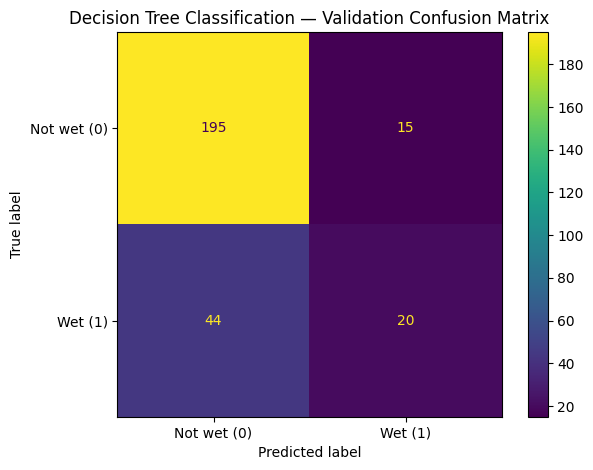

In [11]:
# Plot the validation confusion matrix to see which types of mistakes the model makes.
ConfusionMatrixDisplay.from_predictions(
    y_class_val,
    class_val_predictions,
    display_labels=["Not wet (0)", "Wet (1)"],
    values_format="d",
)
plt.title("Decision Tree Classification — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

### What does the confusion matrix mean?

- **True positive (TP):** predicted wet, and it was wet under our threshold definition.
- **False positive (FP):** predicted wet, but it was not wet.
- **False negative (FN):** predicted not wet, but it was wet.
- **True negative (TN):** predicted not wet, and it was not wet.

For an early-warning use case, false negatives may be important, but false positives can also create unnecessary response costs. The best evaluation metric depends on the intended decision. Do not select a metric only because it produces a high number.

## 10. Visualise the tree: root, branches and leaves

The tree diagram makes the sequence of feature-based decisions visible. Each node shows the split condition, impurity, number of training observations and class counts (for a classifier). Leaf nodes return a class prediction.

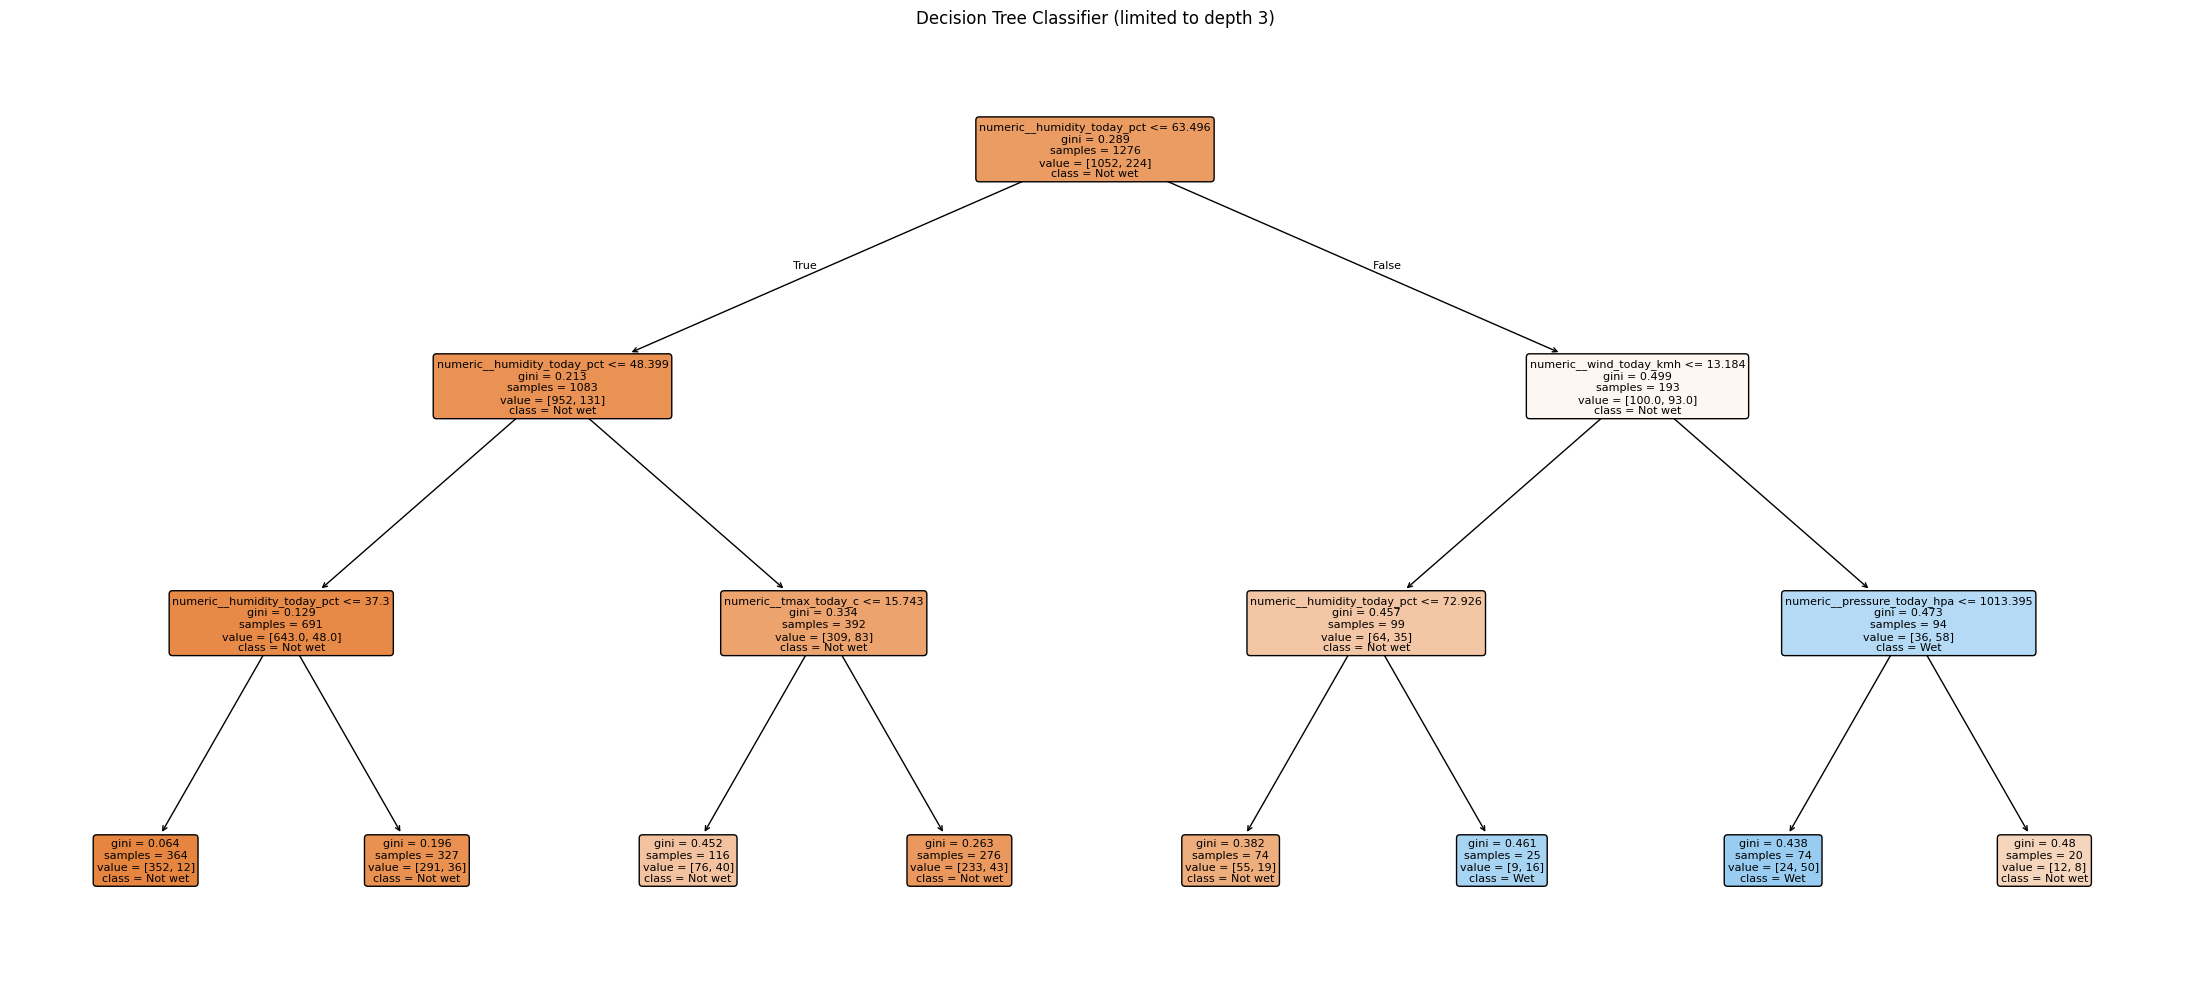

In [12]:
# Get the output feature names after one-hot encoding so the diagram is correctly labelled.
transformed_feature_names = classifier_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Draw the first few levels of the trained classification tree.
plt.figure(figsize=(22, 10))
plot_tree(
    classifier_pipeline.named_steps["tree"],
    feature_names=transformed_feature_names,
    class_names=["Not wet", "Wet"],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    fontsize=8,
)
plt.title("Decision Tree Classifier (limited to depth 3)")
plt.tight_layout()
plt.show()

In [13]:
# Convert the learned tree into readable text rules.
# This is useful for discussing the conditions learned by the model.
rules = export_text(
    classifier_pipeline.named_steps["tree"],
    feature_names=list(transformed_feature_names),
    max_depth=3,
)
print(rules)

|--- numeric__humidity_today_pct <= 63.50
|   |--- numeric__humidity_today_pct <= 48.40
|   |   |--- numeric__humidity_today_pct <= 37.30
|   |   |   |--- class: 0
|   |   |--- numeric__humidity_today_pct >  37.30
|   |   |   |--- class: 0
|   |--- numeric__humidity_today_pct >  48.40
|   |   |--- numeric__tmax_today_c <= 15.74
|   |   |   |--- class: 0
|   |   |--- numeric__tmax_today_c >  15.74
|   |   |   |--- class: 0
|--- numeric__humidity_today_pct >  63.50
|   |--- numeric__wind_today_kmh <= 13.18
|   |   |--- numeric__humidity_today_pct <= 72.93
|   |   |   |--- class: 0
|   |   |--- numeric__humidity_today_pct >  72.93
|   |   |   |--- class: 1
|   |--- numeric__wind_today_kmh >  13.18
|   |   |--- numeric__pressure_today_hpa <= 1013.40
|   |   |   |--- class: 1
|   |   |--- numeric__pressure_today_hpa >  1013.40
|   |   |   |--- class: 0



**How to read a decision rule:** A condition such as `numeric__humidity_today_pct <= ...` sends an observation down one branch if the condition is true and the other branch if it is false. Continue through the branches until reaching a leaf. The leaf returns the predicted class. Threshold values learned from this synthetic data are illustrative and should not be treated as scientific thresholds for Syria.

## 11. Compare Gini and entropy

Both criteria aim to improve the purity of child nodes during classification. We can train two otherwise similar models and compare validation results. The comparison is illustrative; a small difference does not establish that one criterion is always better.

In [14]:
# Train one shallow tree using Gini impurity and one using entropy.
criterion_results = []
for criterion in ["gini", "entropy"]:
    # Use the same preprocessing, depth and leaf-size rule for a fair comparison.
    model = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("tree", DecisionTreeClassifier(
            criterion=criterion,
            max_depth=3,
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
        )),
    ])

    # Fit on training data and evaluate on the validation period.
    model.fit(X_train, y_class_train)
    predictions = model.predict(X_val)

    # Collect several metrics instead of relying on accuracy alone.
    criterion_results.append({
        "criterion": criterion,
        "accuracy": accuracy_score(y_class_val, predictions),
        "precision_wet": precision_score(y_class_val, predictions, zero_division=0),
        "recall_wet": recall_score(y_class_val, predictions, zero_division=0),
        "f1_wet": f1_score(y_class_val, predictions, zero_division=0),
    })

# Display the validation comparison in a table.
criterion_results_df = pd.DataFrame(criterion_results).set_index("criterion")
display(criterion_results_df.round(3))

,accuracy,precision_wet,recall_wet,f1_wet
criterion,,,,
gini,0.785,0.571,0.312,0.404
entropy,0.792,0.600,0.328,0.424


## 12. Stopping criteria and overfitting

Decision trees can keep splitting until they fit the training data very closely. That may not help with new observations.

Common ways to control tree growth include:
- `max_depth`: the maximum number of split levels.
- `min_samples_split`: the minimum number of observations required to split a node.
- `min_samples_leaf`: the minimum number of training observations allowed in a leaf.
- `max_leaf_nodes`: a cap on the total number of leaves.
- `min_impurity_decrease`: require a minimum impurity improvement before splitting.

These settings are **hyperparameters**. They are chosen during model development; the tree learns its split thresholds from training data.

,train_accuracy,validation_accuracy,train_f1_wet,validation_f1_wet
model,,,,
Shallow tree (depth 3),0.85,0.785,0.409,0.404
Unrestricted tree,1.00,0.777,1.000,0.512


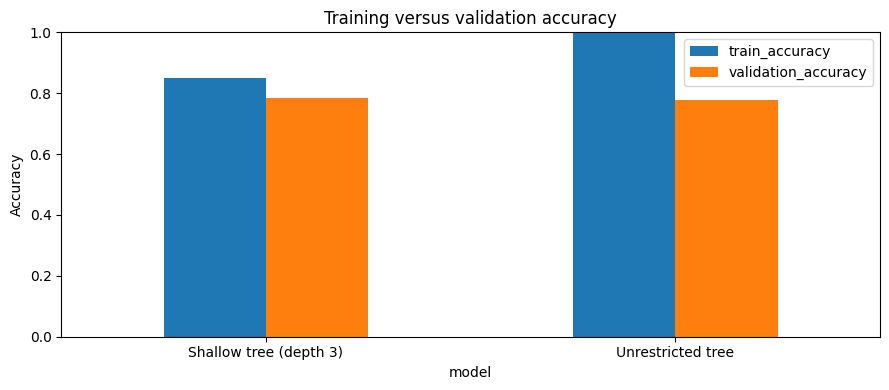

In [15]:
# Compare a small tree with an unrestricted tree to illustrate possible overfitting.
# Both models use the same preprocessing and training period.
overfit_models = {
    "Shallow tree (depth 3)": DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=20, random_state=RANDOM_STATE
    ),
    "Unrestricted tree": DecisionTreeClassifier(
        max_depth=None, min_samples_leaf=1, random_state=RANDOM_STATE
    ),
}

overfit_rows = []
for label, tree_model in overfit_models.items():
    # Fit preprocessing and tree only on the training data.
    pipe = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("tree", tree_model),
    ])
    pipe.fit(X_train, y_class_train)

    # Measure performance on both training and validation dates.
    train_pred = pipe.predict(X_train)
    val_pred = pipe.predict(X_val)
    overfit_rows.append({
        "model": label,
        "train_accuracy": accuracy_score(y_class_train, train_pred),
        "validation_accuracy": accuracy_score(y_class_val, val_pred),
        "train_f1_wet": f1_score(y_class_train, train_pred, zero_division=0),
        "validation_f1_wet": f1_score(y_class_val, val_pred, zero_division=0),
    })

overfit_results = pd.DataFrame(overfit_rows).set_index("model")
display(overfit_results.round(3))

# Plot training vs validation accuracy to make a large generalisation gap easier to notice.
overfit_results[["train_accuracy", "validation_accuracy"]].plot(kind="bar", figsize=(9, 4))
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Training versus validation accuracy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Choose tree depth using validation data

We should not use the test set to pick a hyperparameter. The next cell tries several depths on the training set and compares the results on the validation set. For this classroom example, we select the depth with the highest validation F1-score for the wet-day class. Another project may prioritise recall, precision, cost or another metric.

,max_depth,validation_accuracy,validation_precision_wet,validation_recall_wet,validation_f1_wet
0,1,0.766,0.000,0.000,0.000
1,2,0.770,0.514,0.281,0.364
2,3,0.785,0.571,0.312,0.404
3,4,0.759,0.481,0.391,0.431
4,5,0.763,0.489,0.359,0.414
5,6,0.763,0.489,0.359,0.414
6,8,0.763,0.489,0.359,0.414
7,10,0.763,0.489,0.359,0.414
8,None,0.763,0.489,0.359,0.414


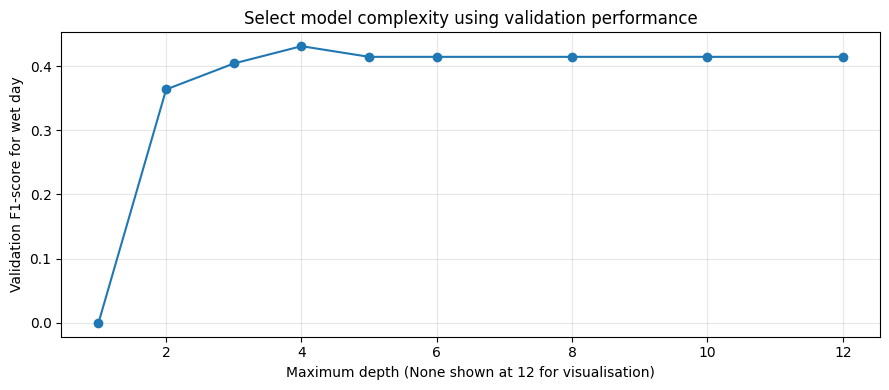

Selected maximum depth based on validation F1: 4


In [16]:
# Try a small set of maximum depths; None allows the tree to grow without a depth limit.
depth_candidates = [1, 2, 3, 4, 5, 6, 8, 10, None]
depth_results = []

for depth in depth_candidates:
    # Configure a tree with the chosen depth and a minimum leaf size to limit tiny leaves.
    tree_model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        min_samples_leaf=20,
        random_state=RANDOM_STATE,
    )

    # Keep preprocessing inside the pipeline to avoid leakage.
    pipe = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("tree", tree_model),
    ])
    pipe.fit(X_train, y_class_train)

    # Evaluate only on the validation data when choosing the depth.
    val_predictions = pipe.predict(X_val)
    depth_results.append({
        "max_depth": "None" if depth is None else str(depth),
        "validation_accuracy": accuracy_score(y_class_val, val_predictions),
        "validation_precision_wet": precision_score(y_class_val, val_predictions, zero_division=0),
        "validation_recall_wet": recall_score(y_class_val, val_predictions, zero_division=0),
        "validation_f1_wet": f1_score(y_class_val, val_predictions, zero_division=0),
    })

depth_results_df = pd.DataFrame(depth_results)
display(depth_results_df.round(3))

# Plot how validation F1 changes with the tree depth candidates.
plot_depth_df = depth_results_df.copy()
plot_depth_df["depth_numeric"] = plot_depth_df["max_depth"].replace("None", "12").astype(int)
plot_depth_df = plot_depth_df.sort_values("depth_numeric")
plt.figure(figsize=(9, 4))
plt.plot(plot_depth_df["depth_numeric"], plot_depth_df["validation_f1_wet"], marker="o")
plt.xlabel("Maximum depth (None shown at 12 for visualisation)")
plt.ylabel("Validation F1-score for wet day")
plt.title("Select model complexity using validation performance")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Pick the depth with the highest validation F1-score; retain None if it was best.
best_row_idx = depth_results_df["validation_f1_wet"].idxmax()
best_depth_label = depth_results_df.loc[best_row_idx, "max_depth"]
best_depth = None if best_depth_label == "None" else int(best_depth_label)
print("Selected maximum depth based on validation F1:", best_depth)

## 13. Final classification evaluation on the held-out test period

After choosing a model setting on validation data, refit the chosen model using all development data (training + validation). Then evaluate it on the untouched test period. Do not adjust the tree depth based on the test score.

Final test classification results
Accuracy:  0.931
Precision: 0.333
Recall:    0.118
F1-score:  0.174

Test classification report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       257
           1       0.33      0.12      0.17        17

    accuracy                           0.93       274
   macro avg       0.64      0.55      0.57       274
weighted avg       0.91      0.93      0.91       274

Baseline test accuracy: 0.938


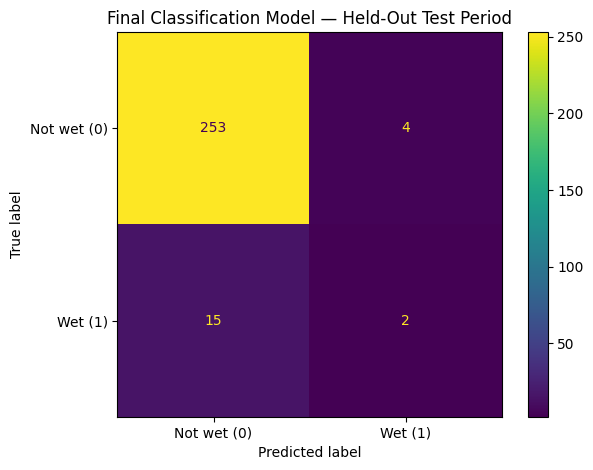

In [17]:
# Combine training and validation data after model selection is complete.
X_trainval = pd.concat([X_train, X_val], axis=0)
y_class_trainval = pd.concat([y_class_train, y_class_val], axis=0)

# Build the final classifier with the selected depth.
final_classifier = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("tree", DecisionTreeClassifier(
        criterion="gini",
        max_depth=best_depth,
        min_samples_leaf=20,
        random_state=RANDOM_STATE,
    )),
])

# Refit on the full development period and evaluate once on the later test period.
final_classifier.fit(X_trainval, y_class_trainval)
test_class_predictions = final_classifier.predict(X_test)

# Calculate final test metrics for the wet-day positive class.
print("Final test classification results")
print(f"Accuracy:  {accuracy_score(y_class_test, test_class_predictions):.3f}")
print(f"Precision: {precision_score(y_class_test, test_class_predictions, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_class_test, test_class_predictions, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_class_test, test_class_predictions, zero_division=0):.3f}")
print("\nTest classification report:")
print(classification_report(y_class_test, test_class_predictions, zero_division=0))

# Compare the tree to a majority-class baseline fitted on development data.
final_class_baseline = DummyClassifier(strategy="most_frequent")
final_class_baseline.fit(X_trainval, y_class_trainval)
baseline_test_predictions = final_class_baseline.predict(X_test)
print("Baseline test accuracy:", round(accuracy_score(y_class_test, baseline_test_predictions), 3))

# Plot the final test confusion matrix.
ConfusionMatrixDisplay.from_predictions(
    y_class_test,
    test_class_predictions,
    display_labels=["Not wet (0)", "Wet (1)"],
    values_format="d",
)
plt.title("Final Classification Model — Held-Out Test Period")
plt.tight_layout()
plt.show()

## 14. Feature importance and interpretation

For a decision tree, feature importance summarises how much a feature contributes to impurity reduction across the fitted tree. It can offer a quick view of what the model used, but it is not proof of causality and can be biased towards some feature types or split opportunities.

With one-hot encoding, a categorical feature becomes multiple indicator columns. Their importance values may be distributed across those encoded columns.

,feature,importance
2,numeric__humidity_today_pct,0.7241
3,numeric__pressure_today_hpa,0.0887
0,numeric__rain_today_mm,0.0736
4,numeric__wind_today_kmh,0.0690
1,numeric__tmax_today_c,0.0447
5,categorical__season_autumn,0.0000
6,categorical__season_spring,0.0000
7,categorical__season_summer,0.0000
8,categorical__season_winter,0.0000


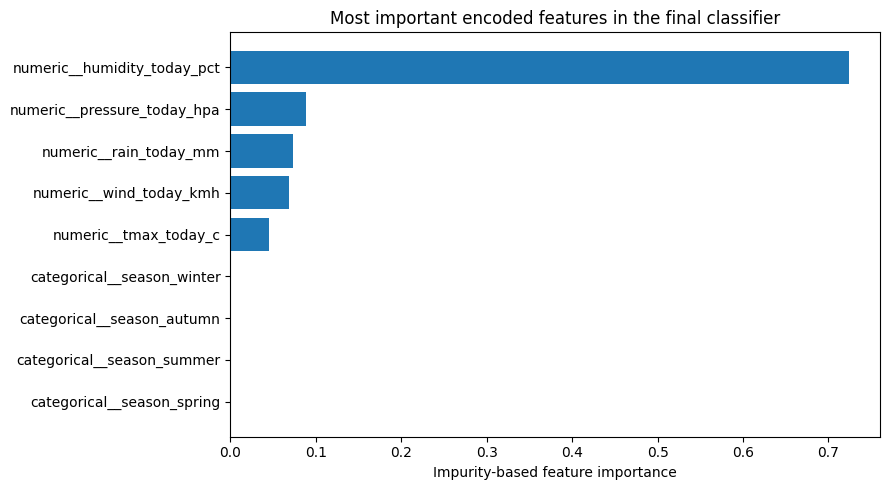

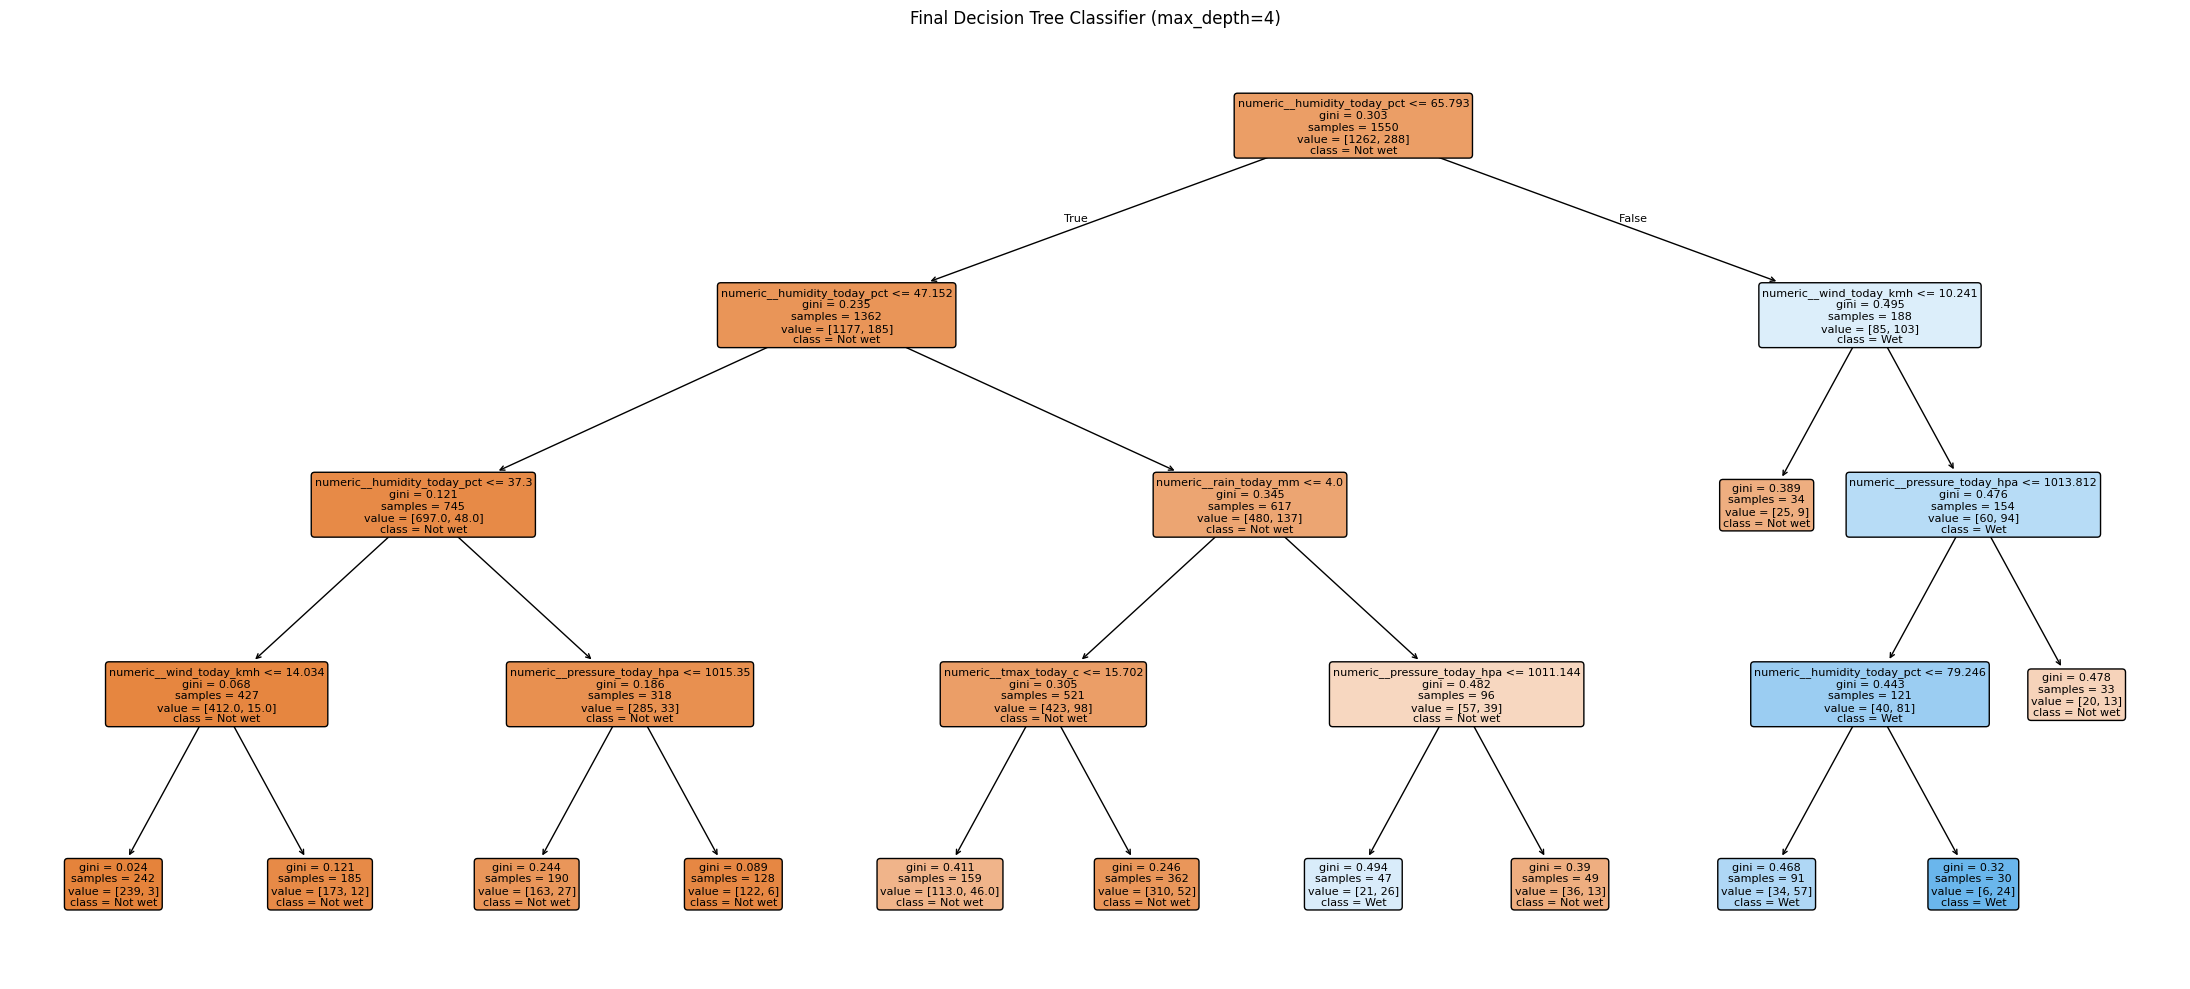

In [18]:
# Get encoded feature names for the final fitted preprocessing pipeline.
final_feature_names = final_classifier.named_steps["preprocessor"].get_feature_names_out()

# Pair the tree's impurity-based importances with their transformed feature names.
importance_df = pd.DataFrame({
    "feature": final_feature_names,
    "importance": final_classifier.named_steps["tree"].feature_importances_,
}).sort_values("importance", ascending=False)

display(importance_df.round(4))

# Plot the highest feature importances for a quick classroom discussion.
importance_to_plot = importance_df.head(10).sort_values("importance")
plt.figure(figsize=(9, 5))
plt.barh(importance_to_plot["feature"], importance_to_plot["importance"])
plt.xlabel("Impurity-based feature importance")
plt.title("Most important encoded features in the final classifier")
plt.tight_layout()
plt.show()

# Draw the selected final tree. Deeper trees may require a larger figure to read comfortably.
plt.figure(figsize=(22, 10))
plot_tree(
    final_classifier.named_steps["tree"],
    feature_names=final_feature_names,
    class_names=["Not wet", "Wet"],
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title(f"Final Decision Tree Classifier (max_depth={best_depth})")
plt.tight_layout()
plt.show()

## 15. Decision Tree Regression: predict rainfall amount

A decision tree regressor uses feature thresholds to divide observations into groups. For squared-error regression, each split is chosen to reduce the weighted squared error within the resulting nodes. Each leaf predicts the mean rainfall amount of the training observations that reach it.

Unlike a linear regression model, the predictions are piecewise constant: observations that reach the same leaf receive the same predicted value. This can capture nonlinear patterns, but predictions may be less smooth than those from a linear model.

In [19]:
# First create a simple mean-prediction baseline for regression.
regression_baseline = DummyRegressor(strategy="mean")
regression_baseline.fit(X_train, y_reg_train)
regression_val_baseline = regression_baseline.predict(X_val)

# Create a simple decision tree regressor with a limited depth.
regression_tree_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("tree", DecisionTreeRegressor(
        criterion="squared_error",  # Reduce squared error inside the child nodes.
        max_depth=4,                 # Limit the tree to help control complexity.
        min_samples_leaf=20,         # Avoid predictions based on very small leaves.
        random_state=RANDOM_STATE,
    )),
])

# Fit the regression pipeline on training data only.
regression_tree_pipeline.fit(X_train, y_reg_train)

# Predict rainfall on the training and validation time blocks.
reg_train_predictions = regression_tree_pipeline.predict(X_train)
reg_val_predictions = regression_tree_pipeline.predict(X_val)

# Define a helper to report the most common regression metrics clearly.
def regression_metrics(y_true, y_pred):
    # Calculate metrics in the same units as the target (millimetres for MAE and RMSE).
    return {
        "MAE_mm": mean_absolute_error(y_true, y_pred),
        "RMSE_mm": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

# Display baseline and tree performance on validation dates.
regression_validation_results = pd.DataFrame([
    {"model": "Mean baseline", **regression_metrics(y_reg_val, regression_val_baseline)},
    {"model": "Decision tree (depth 4)", **regression_metrics(y_reg_val, reg_val_predictions)},
]).set_index("model")
display(regression_validation_results.round(3))

,MAE_mm,RMSE_mm,R2
model,,,
Mean baseline,2.165,3.569,-0.008
Decision tree (depth 4),2.003,3.472,0.046


### Tune regression tree depth on validation data

As with classification, use validation data to choose model complexity. Here we use RMSE as the selection metric. Since RMSE gives greater weight to large errors, this choice may or may not match every application's priorities.

,max_depth,MAE_mm,RMSE_mm,R2
0,1,2.003,3.437,0.065
1,2,2.017,3.449,0.058
2,3,2.019,3.477,0.043
3,4,2.003,3.472,0.046
4,5,1.984,3.529,0.014
5,6,1.967,3.505,0.028
6,8,1.988,3.499,0.031
7,10,1.998,3.510,0.025
8,None,1.998,3.511,0.024


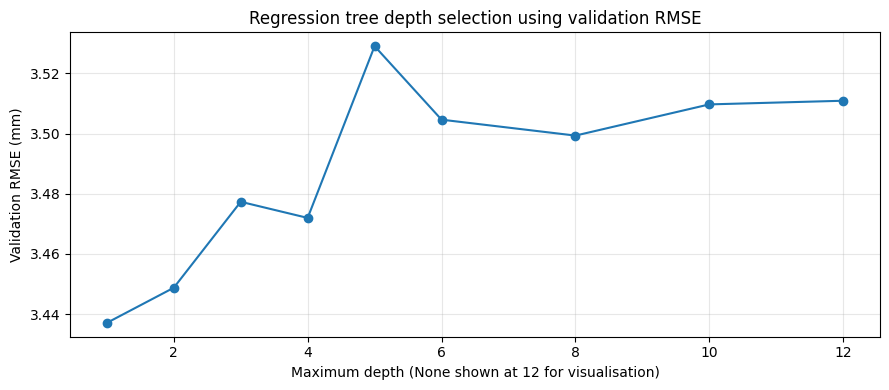

Selected regression tree depth: 1


In [20]:
# Try several depths and measure validation RMSE for each one.
reg_depth_rows = []
for depth in depth_candidates:
    # Build a new pipeline for this candidate depth.
    pipe = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("tree", DecisionTreeRegressor(
            criterion="squared_error",
            max_depth=depth,
            min_samples_leaf=20,
            random_state=RANDOM_STATE,
        )),
    ])

    # Fit on the training period only.
    pipe.fit(X_train, y_reg_train)

    # Evaluate on the validation period only.
    predictions = pipe.predict(X_val)
    metrics = regression_metrics(y_reg_val, predictions)
    reg_depth_rows.append({
        "max_depth": "None" if depth is None else str(depth),
        **metrics,
    })

reg_depth_results = pd.DataFrame(reg_depth_rows)
display(reg_depth_results.round(3))

# Plot validation RMSE for each tested maximum depth.
reg_depth_plot = reg_depth_results.copy()
reg_depth_plot["depth_numeric"] = reg_depth_plot["max_depth"].replace("None", "12").astype(int)
reg_depth_plot = reg_depth_plot.sort_values("depth_numeric")
plt.figure(figsize=(9, 4))
plt.plot(reg_depth_plot["depth_numeric"], reg_depth_plot["RMSE_mm"], marker="o")
plt.xlabel("Maximum depth (None shown at 12 for visualisation)")
plt.ylabel("Validation RMSE (mm)")
plt.title("Regression tree depth selection using validation RMSE")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Select the candidate with the lowest validation RMSE.
best_reg_row = reg_depth_results["RMSE_mm"].idxmin()
best_reg_depth_label = reg_depth_results.loc[best_reg_row, "max_depth"]
best_reg_depth = None if best_reg_depth_label == "None" else int(best_reg_depth_label)
print("Selected regression tree depth:", best_reg_depth)

In [21]:
# Combine training and validation data after choosing the regression tree depth.
y_reg_trainval = pd.concat([y_reg_train, y_reg_val], axis=0)

# Build the final regression pipeline using the selected depth.
final_regressor = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("tree", DecisionTreeRegressor(
        criterion="squared_error",
        max_depth=best_reg_depth,
        min_samples_leaf=20,
        random_state=RANDOM_STATE,
    )),
])

# Refit on the full development period, then predict on later held-out test observations.
final_regressor.fit(X_trainval, y_reg_trainval)
test_reg_predictions = final_regressor.predict(X_test)

# Evaluate the final model and a mean baseline on exactly the same test observations.
final_reg_baseline = DummyRegressor(strategy="mean")
final_reg_baseline.fit(X_trainval, y_reg_trainval)
test_reg_baseline_predictions = final_reg_baseline.predict(X_test)

final_regression_results = pd.DataFrame([
    {"model": "Mean baseline", **regression_metrics(y_reg_test, test_reg_baseline_predictions)},
    {"model": "Decision tree", **regression_metrics(y_reg_test, test_reg_predictions)},
]).set_index("model")

print("Final regression evaluation on the held-out test period")
display(final_regression_results.round(3))

Final regression evaluation on the held-out test period


,MAE_mm,RMSE_mm,R2
model,,,
Mean baseline,1.434,1.698,-0.470
Decision tree,1.078,1.389,0.016


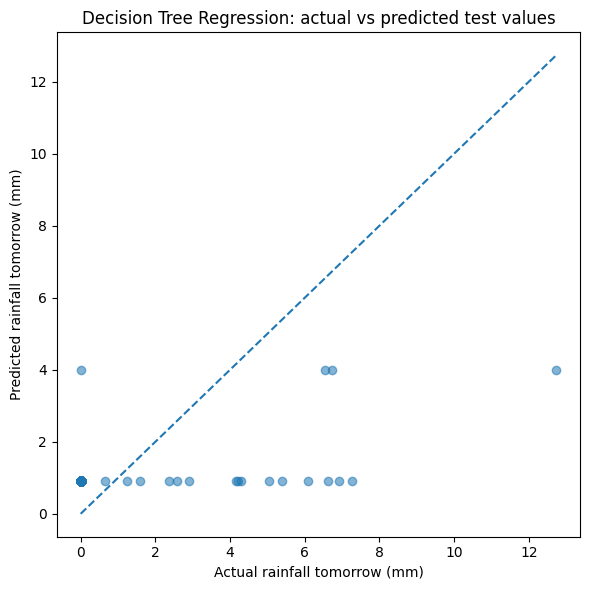

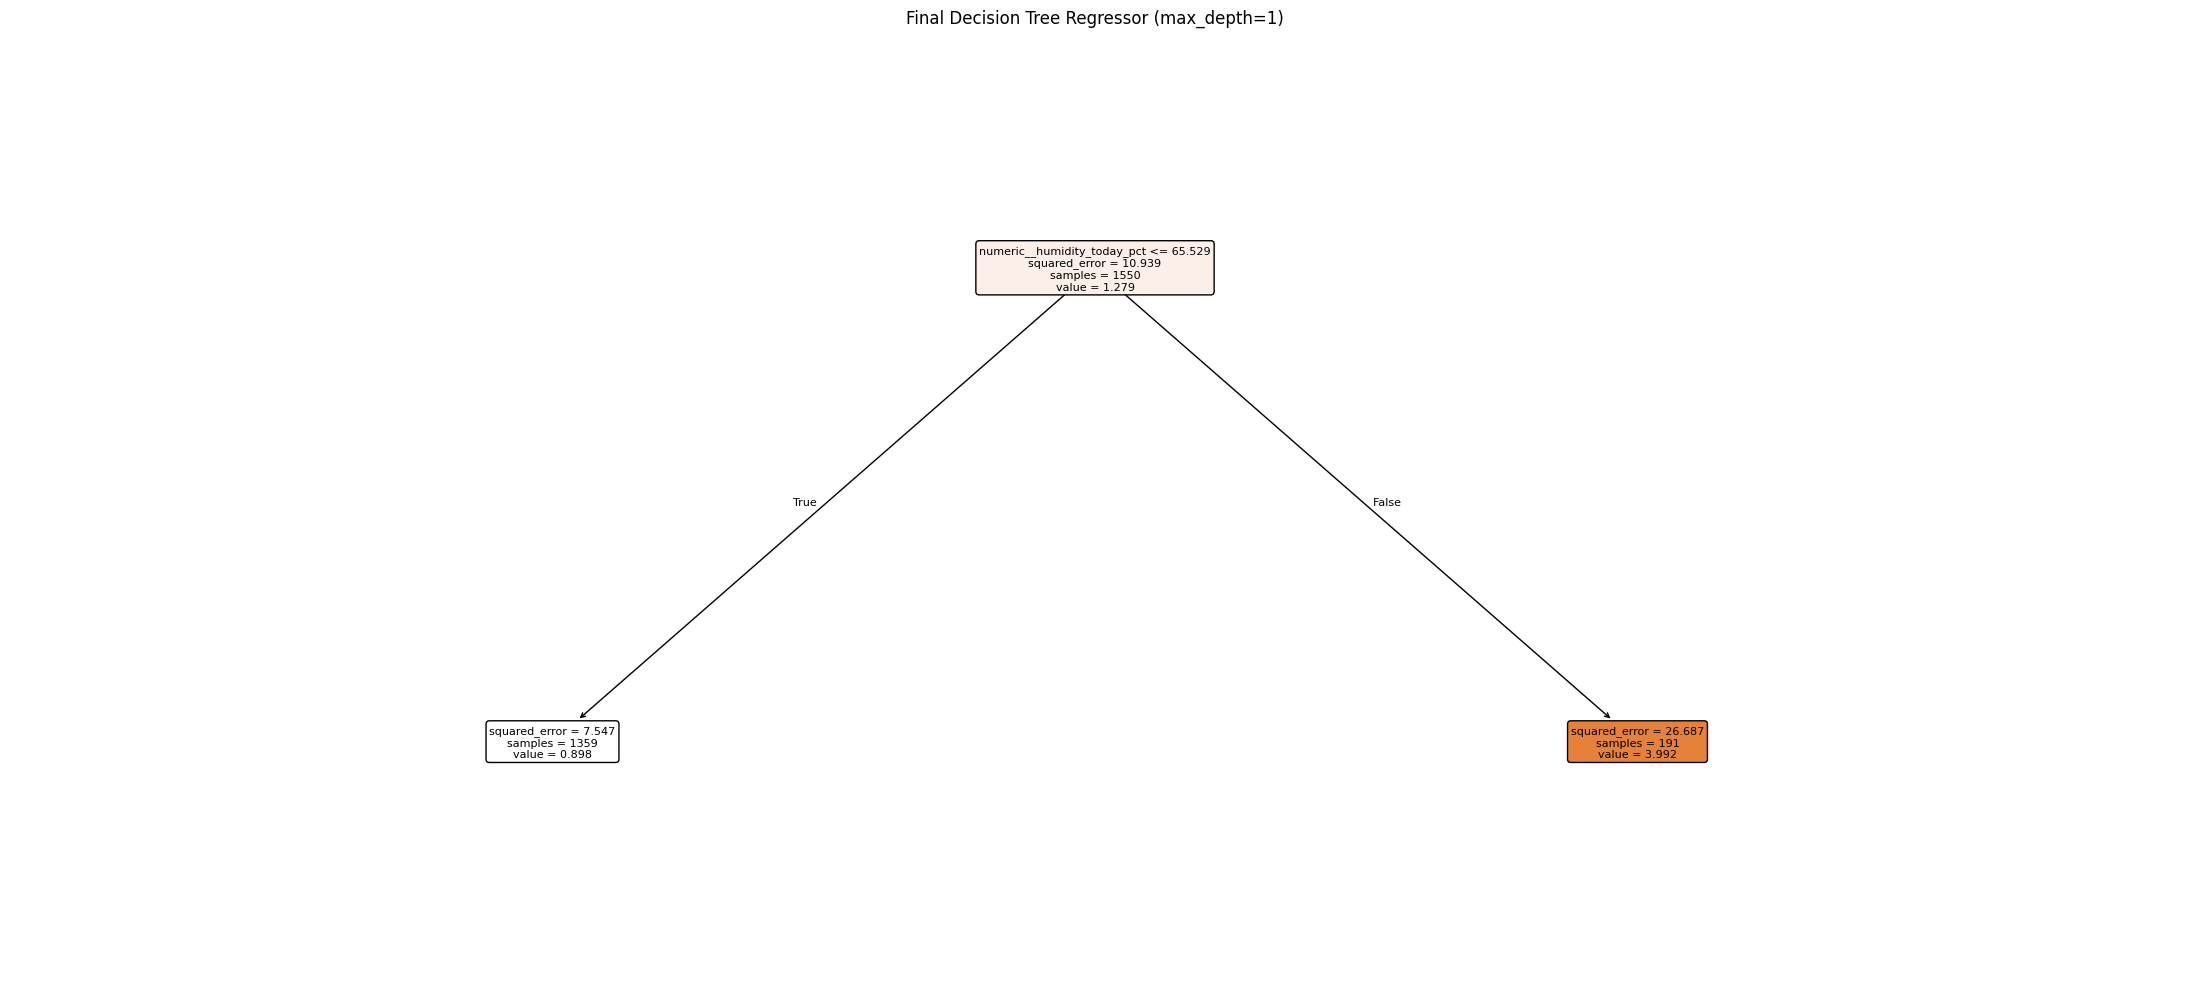

In [22]:
# Compare actual and predicted rainfall values on the held-out test period.
# Each plotted point is one test observation; a perfect prediction would lie on the diagonal.
plt.figure(figsize=(6, 6))
plt.scatter(y_reg_test, test_reg_predictions, alpha=0.55)

# Draw a reference diagonal using the range observed in actual and predicted values.
max_value = max(float(y_reg_test.max()), float(np.max(test_reg_predictions)))
plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Actual rainfall tomorrow (mm)")
plt.ylabel("Predicted rainfall tomorrow (mm)")
plt.title("Decision Tree Regression: actual vs predicted test values")
plt.tight_layout()
plt.show()

# Plot the regression tree so students can see its learned numerical split rules.
reg_feature_names = final_regressor.named_steps["preprocessor"].get_feature_names_out()
plt.figure(figsize=(22, 10))
plot_tree(
    final_regressor.named_steps["tree"],
    feature_names=reg_feature_names,
    filled=True,
    rounded=True,
    impurity=True,
    fontsize=8,
)
plt.title(f"Final Decision Tree Regressor (max_depth={best_reg_depth})")
plt.tight_layout()
plt.show()

## 16. What is an ensemble tree? Brief introduction to Random Forest

The presentation also introduces ensemble trees, including Random Forest and boosted trees.

A **Random Forest** trains multiple decision trees using bootstrap samples and random subsets of features. For classification, the trees' predictions are combined (commonly by voting); for regression, their numerical predictions are averaged. Combining trees often improves stability compared with a single tree, although it makes the overall model harder to interpret.

The following optional cell compares a Random Forest classifier with the selected single decision tree. It is fitted on training data and evaluated on the validation period. This is only a brief introduction; it is not a full lesson on Random Forest or XGBoost.

In [23]:
# Build a Random Forest classifier as an optional extension to the single-tree example.
random_forest_classifier = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("forest", RandomForestClassifier(
        n_estimators=100,       # Train 100 trees and combine their predictions.
        max_depth=best_depth,   # Use the selected depth as a simple complexity constraint.
        min_samples_leaf=10,    # Avoid extremely small leaves in individual trees.
        random_state=RANDOM_STATE,
        n_jobs=-1,              # Use available CPU cores where supported.
        class_weight="balanced", # Give minority classes more weight during training.
    )),
])

# Fit the forest on the training period and evaluate on validation data.
random_forest_classifier.fit(X_train, y_class_train)
rf_val_predictions = random_forest_classifier.predict(X_val)

# Compare the two classifiers on the same validation observations.
# The single tree here is the original depth-3 demonstration model trained on training data only.
ensemble_comparison = pd.DataFrame([
    {
        "model": "Single decision tree (depth 3)",
        "accuracy": accuracy_score(y_class_val, classifier_pipeline.predict(X_val)),
        "precision_wet": precision_score(y_class_val, classifier_pipeline.predict(X_val), zero_division=0),
        "recall_wet": recall_score(y_class_val, classifier_pipeline.predict(X_val), zero_division=0),
        "f1_wet": f1_score(y_class_val, classifier_pipeline.predict(X_val), zero_division=0),
    },
    {
        "model": "Random Forest (optional)",
        "accuracy": accuracy_score(y_class_val, rf_val_predictions),
        "precision_wet": precision_score(y_class_val, rf_val_predictions, zero_division=0),
        "recall_wet": recall_score(y_class_val, rf_val_predictions, zero_division=0),
        "f1_wet": f1_score(y_class_val, rf_val_predictions, zero_division=0),
    },
]).set_index("model")

display(ensemble_comparison.round(3))

,accuracy,precision_wet,recall_wet,f1_wet
model,,,,
Single decision tree (depth 3),0.785,0.571,0.312,0.404
Random Forest (optional),0.719,0.436,0.688,0.533


## 17. Decision trees: strengths, limitations and responsible use

### Strengths
- Can learn nonlinear decision rules and feature interactions.
- Usually needs little feature scaling.
- Supports numerical features and, after encoding, categorical features.
- A small tree can be visualised and explained.
- Works for both classification and regression on tabular data.

### Limitations
- Deep trees can overfit.
- Small changes in data may lead to a different tree.
- A single tree may be less accurate or stable than ensemble methods.
- Impurity-based feature importance does not show causality.
- Synthetic or biased data leads to misleading conclusions regardless of the algorithm.

### Climate-specific cautions
- This notebook's data is synthetic and does not validate a model for Syria.
- Real climate data may contain missing dates, station gaps, measurement errors, spatial differences and changing seasonal relationships.
- Forecasting evaluation should preserve time order and, where relevant, test generalisation to other locations.
- A model prediction should not be presented as an official forecast or warning without rigorous external validation and domain review.

## 18. Student exercises

Try these tasks after running the notebook:

1. Change `max_depth` from 3 to 2 and then to 6. What changes in the tree diagram and validation metrics?
2. Change `min_samples_leaf` from 20 to 5. Does the model become more complex? Does validation performance improve or worsen?
3. Change the classifier criterion from `"gini"` to `"entropy"`. Compare validation precision, recall and F1-score.
4. Increase the wet-day target threshold from 1.0 mm to 5.0 mm. How does the class balance change, and why might accuracy alone become less useful?
5. For regression, compare the decision tree with the mean baseline. Does it improve MAE and RMSE on test data?
6. Explain the difference between a leaf's class prediction in classification and its average target prediction in regression.
7. Propose one validation split that would test generalisation to an unseen weather station rather than only later dates at the same station.

### Quick quiz

**A.** What are the root node, branch and leaf node?

**B.** What does information gain measure?

**C.** Why does one-hot encoding appear in this notebook?

**D.** Which hyperparameter limits the maximum number of split levels?

**E.** Why should the test set not be used to select the best tree depth?

**Suggested answers:** A — first split, path/outcome of a split, final prediction node. B — reduction in entropy after a split, relative to the weighted child nodes. C — scikit-learn's tree implementation needs numeric inputs, so seasons are converted to indicator columns. D — `max_depth`. E — using the test set for model selection makes the reported final test score less independent.

## 19. Summary

In this notebook you have:

1. Defined climate-related supervised learning problems for classification and regression.
2. Generated a reproducible synthetic weather dataset and built next-day targets.
3. Split data chronologically to mimic forecasting on future dates.
4. Applied imputation and one-hot encoding inside a scikit-learn pipeline.
5. Trained and evaluated a Decision Tree Classifier and Decision Tree Regressor.
6. Calculated and interpreted Gini impurity, entropy and information gain.
7. Visualised the tree, explored learned rules and examined feature importance.
8. Investigated stopping criteria, overfitting and validation-based depth selection.
9. Compared against simple baselines and briefly introduced Random Forests.

**Final takeaway:** A decision tree is easy to start with, but a useful climate model also requires a well-defined target, trustworthy data, fair evaluation, suitable baselines and careful communication of uncertainty and limitations.